In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

from pathlib import Path
from tensorflow.keras.models import load_model

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
PROJECT_ROOT = Path.cwd().parent

PROCESSED_DIR = PROJECT_ROOT / "dataset" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports" / "evaluation"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_ROOT)

Project: d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator


In [3]:
X_test = np.load(
    PROCESSED_DIR / "X_test.npy"
).astype("float32")

y_test_placement = np.load(
    PROCESSED_DIR / "y_test_placement.npy"
)

y_test_readiness = np.load(
    PROCESSED_DIR / "y_test_readiness.npy"
)

y_test_domain = np.load(
    PROCESSED_DIR / "y_test_domain.npy"
)

y_test_employability = np.load(
    PROCESSED_DIR / "y_test_employability.npy"
).astype("float32")

readiness_encoder = joblib.load(
    MODEL_DIR / "readiness_encoder.joblib"
)

domain_encoder = joblib.load(
    MODEL_DIR / "domain_encoder.joblib"
)

print("Test dataset loaded successfully!")
print("Test features:", X_test.shape)
print("Test records:", len(X_test))

Test dataset loaded successfully!
Test features: (2250, 65)
Test records: 2250


In [4]:
models = {
    "placement_logistic": joblib.load(
        MODEL_DIR / "baseline_placement_logistic_regression.joblib"
    ),

    "placement_tree": joblib.load(
        MODEL_DIR / "baseline_placement_decision_tree.joblib"
    ),

    "placement_forest": joblib.load(
        MODEL_DIR / "baseline_placement_random_forest.joblib"
    ),

    "readiness_logistic": joblib.load(
        MODEL_DIR / "baseline_career_readiness_logistic_regression.joblib"
    ),

    "readiness_tree": joblib.load(
        MODEL_DIR / "baseline_career_readiness_decision_tree.joblib"
    ),

    "readiness_forest": joblib.load(
        MODEL_DIR / "baseline_career_readiness_random_forest.joblib"
    ),

    "domain_logistic": joblib.load(
        MODEL_DIR / "baseline_career_domain_logistic_regression.joblib"
    ),

    "domain_tree": joblib.load(
        MODEL_DIR / "baseline_career_domain_decision_tree.joblib"
    ),

    "domain_forest": joblib.load(
        MODEL_DIR / "baseline_career_domain_random_forest.joblib"
    ),

    "employability_linear": joblib.load(
        MODEL_DIR / "baseline_employability_linear_regression.joblib"
    ),

    "employability_tree": joblib.load(
        MODEL_DIR / "baseline_employability_decision_tree.joblib"
    ),

    "employability_forest": joblib.load(
        MODEL_DIR / "baseline_employability_random_forest.joblib"
    )
}

print("All 12 baseline models loaded!")

All 12 baseline models loaded!


In [5]:
ann_models = {
    "placement_original": load_model(
        MODEL_DIR / "ann_placement_final.keras"
    ),

    "placement_weighted": load_model(
        MODEL_DIR / "ann_placement_weighted_final.keras"
    ),

    "readiness": load_model(
        MODEL_DIR / "ann_readiness_final.keras"
    ),

    "domain_original": load_model(
        MODEL_DIR / "ann_domain_final.keras"
    ),

    "domain_weighted": load_model(
        MODEL_DIR / "ann_domain_weighted_final.keras"
    ),

    "employability": load_model(
        MODEL_DIR / "ann_employability_final.keras"
    )
}

print("All ANN models loaded!")

All ANN models loaded!


In [6]:
def evaluate_classifier(model, X, y_true, model_name, class_names=None):

    probabilities = model.predict(X, verbose=0) if hasattr(model, "layers") else model.predict_proba(X)

    predictions = np.argmax(probabilities, axis=1) if probabilities.ndim == 2 else (probabilities >= 0.5).astype(int)

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision_Macro": precision_score(y_true, predictions, average="macro", zero_division=0),
        "Recall_Macro": recall_score(y_true, predictions, average="macro", zero_division=0),
        "F1_Macro": f1_score(y_true, predictions, average="macro", zero_division=0),
        "F1_Weighted": f1_score(y_true, predictions, average="weighted", zero_division=0)
    }

    if probabilities.ndim == 2:
        if probabilities.shape[1] == 2:
            results["ROC_AUC"] = roc_auc_score(y_true, probabilities[:, 1])
        else:
            results["ROC_AUC"] = roc_auc_score(
                y_true,
                probabilities,
                multi_class="ovr",
                average="macro",
                labels=np.arange(probabilities.shape[1])
            )

    return results, predictions

In [7]:
placement_models = {
    "Logistic Regression": models["placement_logistic"],
    "Decision Tree": models["placement_tree"],
    "Random Forest": models["placement_forest"],
    "Original ANN": ann_models["placement_original"],
    "Class-Weighted ANN": ann_models["placement_weighted"]
}

placement_test_results = []
placement_predictions = {}

for name, model in placement_models.items():

    result, prediction = evaluate_classifier(
        model,
        X_test,
        y_test_placement,
        name
    )

    placement_test_results.append(result)
    placement_predictions[name] = prediction

placement_test_df = pd.DataFrame(placement_test_results)

display(
    placement_test_df.sort_values(
        "F1_Macro",
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Weighted,ROC_AUC
1,Decision Tree,0.5480,0.5154,0.5157,0.5155,0.5495,0.5157
0,Logistic Regression,0.6409,0.5896,0.5409,0.5109,0.5792,0.6177
2,Random Forest,0.6422,0.5935,0.5378,0.5016,0.5734,0.6147
3,Original ANN,0.6356,0.3178,0.5000,0.3886,0.4939,0.6062
4,Class-Weighted ANN,0.6356,0.3178,0.5000,0.3886,0.4939,0.6125


In [14]:
readiness_models = {
    "Logistic Regression": models["readiness_logistic"],
    "Decision Tree": models["readiness_tree"],
    "Random Forest": models["readiness_forest"],
    "ANN": ann_models["readiness"]
}

readiness_test_results = []
readiness_predictions = {}

for name, model in readiness_models.items():

    result, prediction = evaluate_classifier(
        model,
        X_test,
        y_test_readiness,
        name
    )

    readiness_test_results.append(result)
    readiness_predictions[name] = prediction

readiness_test_df = pd.DataFrame(readiness_test_results)

display(
    readiness_test_df.sort_values(
        "F1_Macro",
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Weighted,ROC_AUC
0,Logistic Regression,0.7711,0.7831,0.7545,0.7668,0.7706,0.9109
3,ANN,0.7573,0.7555,0.7609,0.7581,0.7573,0.9044
2,Random Forest,0.7338,0.7762,0.6879,0.7161,0.7286,0.8810
1,Decision Tree,0.5929,0.5872,0.5827,0.5849,0.5926,0.6787


In [16]:
best_readiness_name = readiness_test_df.sort_values(
    "F1_Macro",
    ascending=False
).iloc[0]["Model"]

print("Best Readiness Model:", best_readiness_name)

best_readiness_model = readiness_models[best_readiness_name]

best_readiness_predictions = (
    np.argmax(
        best_readiness_model.predict(X_test, verbose=0),
        axis=1
    )
    if hasattr(best_readiness_model, "layers")
    else best_readiness_model.predict(X_test)
)

readiness_class_names = readiness_encoder.classes_

print("Predictions generated:", len(best_readiness_predictions))
print("Classes:", readiness_class_names)

Best Readiness Model: Logistic Regression
Predictions generated: 2250
Classes: ['High' 'Low' 'Moderate']


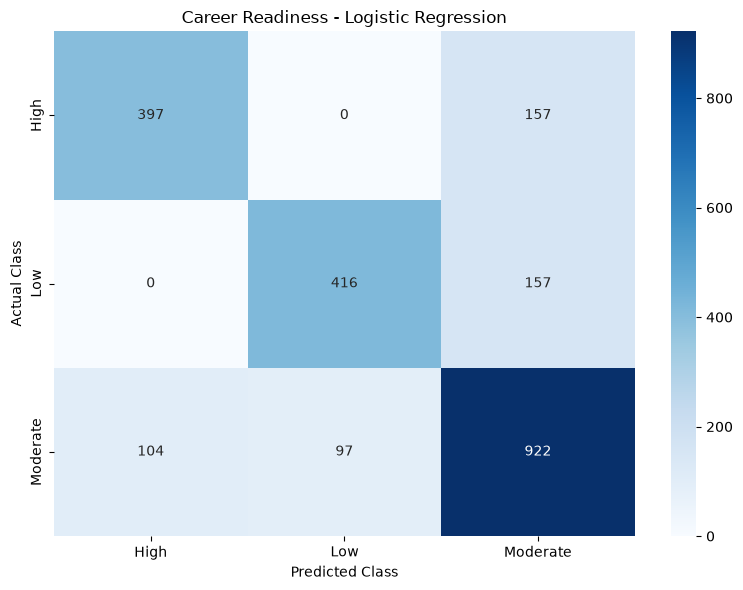

In [17]:
cm = confusion_matrix(
    y_test_readiness,
    best_readiness_predictions,
    labels=np.arange(len(readiness_class_names))
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=readiness_class_names,
    yticklabels=readiness_class_names
)

plt.title(f"Career Readiness - {best_readiness_name}")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

In [18]:
domain_models = {
    "Logistic Regression": models["domain_logistic"],
    "Decision Tree": models["domain_tree"],
    "Random Forest": models["domain_forest"],
    "Original ANN": ann_models["domain_original"],
    "Class-Weighted ANN": ann_models["domain_weighted"]
}

domain_test_results = []
domain_predictions = {}

for name, model in domain_models.items():

    result, prediction = evaluate_classifier(
        model,
        X_test,
        y_test_domain,
        name
    )

    domain_test_results.append(result)
    domain_predictions[name] = prediction

domain_test_df = pd.DataFrame(domain_test_results)

display(
    domain_test_df.sort_values(
        "F1_Macro",
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Weighted,ROC_AUC
4,Class-Weighted ANN,0.2862,0.2650,0.2740,0.2564,0.2996,0.6386
0,Logistic Regression,0.4116,0.3117,0.2510,0.2457,0.3497,0.6693
1,Decision Tree,0.2582,0.1951,0.1963,0.1952,0.2620,0.5190
3,Original ANN,0.4009,0.2870,0.2144,0.1882,0.3053,0.6439
2,Random Forest,0.4124,0.3201,0.2103,0.1731,0.2998,0.6270


Best Career Domain Model: Class-Weighted ANN
                                            precision    recall  f1-score   support

Artificial Intelligence & Machine Learning       0.19      0.17      0.18       235
                           Cloud Computing       0.18      0.30      0.23       220
                             Cybersecurity       0.34      0.22      0.27       445
                              Data Science       0.17      0.29      0.21       230
                      Software Development       0.52      0.33      0.41       865
                              UI/UX Design       0.19      0.32      0.24       255

                                  accuracy                           0.29      2250
                                 macro avg       0.26      0.27      0.26      2250
                              weighted avg       0.34      0.29      0.30      2250



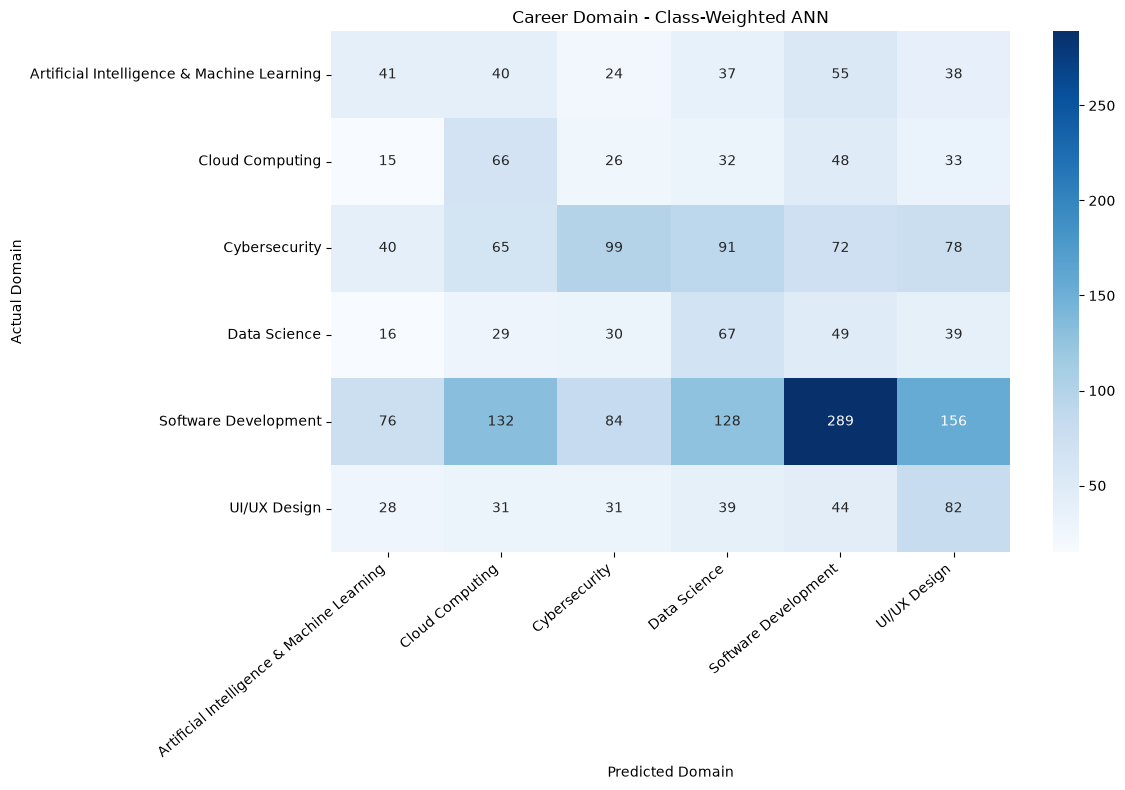

In [19]:
best_domain_name = domain_test_df.sort_values(
    "F1_Macro",
    ascending=False
).iloc[0]["Model"]

best_domain_predictions = domain_predictions[best_domain_name]

domain_class_names = domain_encoder.classes_

print("Best Career Domain Model:", best_domain_name)

print(
    classification_report(
        y_test_domain,
        best_domain_predictions,
        labels=np.arange(len(domain_class_names)),
        target_names=domain_class_names,
        zero_division=0
    )
)

cm = confusion_matrix(
    y_test_domain,
    best_domain_predictions,
    labels=np.arange(len(domain_class_names))
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=domain_class_names,
    yticklabels=domain_class_names
)

plt.title(f"Career Domain - {best_domain_name}")
plt.xlabel("Predicted Domain")
plt.ylabel("Actual Domain")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

In [20]:
employability_models = {
    "Linear Regression": models["employability_linear"],
    "Decision Tree": models["employability_tree"],
    "Random Forest": models["employability_forest"]
}

employability_test_results = []
employability_predictions = {}

for name, model in employability_models.items():

    prediction = model.predict(X_test)

    employability_predictions[name] = prediction

    employability_test_results.append({
        "Model": name,
        "MAE": mean_absolute_error(
            y_test_employability,
            prediction
        ),
        "MSE": mean_squared_error(
            y_test_employability,
            prediction
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_test_employability,
                prediction
            )
        ),
        "R2": r2_score(
            y_test_employability,
            prediction
        )
    })

# ANN prediction
ann_employability_prediction = ann_models[
    "employability"
].predict(X_test, verbose=0).flatten()

ann_employability_prediction = np.clip(
    ann_employability_prediction,
    0,
    100
)

employability_predictions["ANN"] = ann_employability_prediction

employability_test_results.append({
    "Model": "ANN",
    "MAE": mean_absolute_error(
        y_test_employability,
        ann_employability_prediction
    ),
    "MSE": mean_squared_error(
        y_test_employability,
        ann_employability_prediction
    ),
    "RMSE": np.sqrt(
        mean_squared_error(
            y_test_employability,
            ann_employability_prediction
        )
    ),
    "R2": r2_score(
        y_test_employability,
        ann_employability_prediction
    )
})

employability_test_df = pd.DataFrame(
    employability_test_results
)

display(
    employability_test_df.sort_values(
        "MAE"
    ).round(4)
)

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,3.2113,16.1706,4.0213,0.6588
3,ANN,3.3770,18.0780,4.2518,0.6186
2,Random Forest,3.5321,19.5888,4.4259,0.5867
1,Decision Tree,5.1067,40.6861,6.3786,0.1416


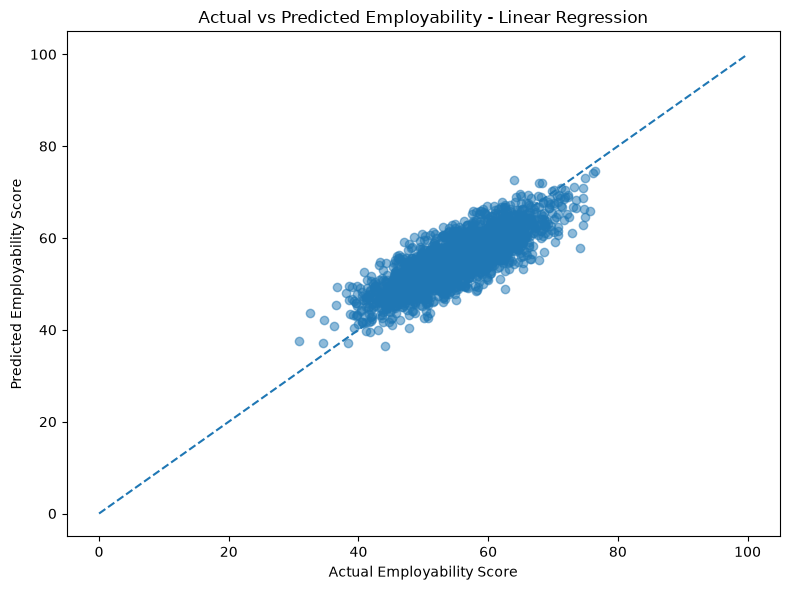

Best Employability Model: Linear Regression


In [21]:
best_regression_name = employability_test_df.sort_values(
    "MAE"
).iloc[0]["Model"]

best_regression_predictions = employability_predictions[
    best_regression_name
]

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_employability,
    best_regression_predictions,
    alpha=0.5
)

plt.plot(
    [0, 100],
    [0, 100],
    linestyle="--"
)

plt.title(
    f"Actual vs Predicted Employability - {best_regression_name}"
)

plt.xlabel("Actual Employability Score")
plt.ylabel("Predicted Employability Score")

plt.tight_layout()
plt.show()

print("Best Employability Model:", best_regression_name)

In [22]:
placement_test_df.to_csv(
    REPORT_DIR / "placement_final_test_results.csv",
    index=False
)

readiness_test_df.to_csv(
    REPORT_DIR / "readiness_final_test_results.csv",
    index=False
)

domain_test_df.to_csv(
    REPORT_DIR / "domain_final_test_results.csv",
    index=False
)

employability_test_df.to_csv(
    REPORT_DIR / "employability_final_test_results.csv",
    index=False
)

print("All final test evaluation reports saved!")

All final test evaluation reports saved!


In [23]:
final_summary = pd.DataFrame([
    {
        "Task": "Placement",
        "Best Model": placement_test_df.sort_values(
            "F1_Macro", ascending=False
        ).iloc[0]["Model"],
        "Selection Metric": "Macro F1",
        "Best Score": placement_test_df["F1_Macro"].max()
    },
    {
        "Task": "Career Readiness",
        "Best Model": readiness_test_df.sort_values(
            "F1_Macro", ascending=False
        ).iloc[0]["Model"],
        "Selection Metric": "Macro F1",
        "Best Score": readiness_test_df["F1_Macro"].max()
    },
    {
        "Task": "Career Domain",
        "Best Model": domain_test_df.sort_values(
            "F1_Macro", ascending=False
        ).iloc[0]["Model"],
        "Selection Metric": "Macro F1",
        "Best Score": domain_test_df["F1_Macro"].max()
    },
    {
        "Task": "Employability Score",
        "Best Model": employability_test_df.sort_values(
            "MAE"
        ).iloc[0]["Model"],
        "Selection Metric": "Lowest MAE",
        "Best Score": employability_test_df["MAE"].min()
    }
])

print("CAREER NAVIGATOR - FINAL TEST MODEL SUMMARY")
print("=" * 75)

display(final_summary.round(4))

final_summary.to_csv(
    REPORT_DIR / "final_model_selection_summary.csv",
    index=False
)

print("Final model summary saved successfully!")

CAREER NAVIGATOR - FINAL TEST MODEL SUMMARY


,Task,Best Model,Selection Metric,Best Score
0,Placement,Decision Tree,Macro F1,0.5155
1,Career Readiness,Logistic Regression,Macro F1,0.7668
2,Career Domain,Class-Weighted ANN,Macro F1,0.2564
3,Employability Score,Linear Regression,Lowest MAE,3.2113


Final model summary saved successfully!


In [24]:
selected_models = {
    "Placement": ("Class-Weighted ANN", placement_test_df, "F1_Macro", "max"),
    "Career Readiness": ("Logistic Regression", readiness_test_df, "F1_Macro", "max"),
    "Career Domain": ("Logistic Regression", domain_test_df, "F1_Macro", "max"),
    "Employability Score": ("Linear Regression", employability_test_df, "MAE", "min")
}

final_model_summary = []

for task, (model_name, results_df, metric, direction) in selected_models.items():

    selected_row = results_df[
        results_df["Model"] == model_name
    ]

    if selected_row.empty:
        raise ValueError(f"{model_name} not found for {task}")

    score = selected_row.iloc[0][metric]

    final_model_summary.append({
        "Task": task,
        "Selected Model": model_name,
        "Selection Basis": "Validation Performance",
        "Test Metric": metric,
        "Test Score": score
    })

final_model_summary_df = pd.DataFrame(final_model_summary)

display(final_model_summary_df.round(4))

final_model_summary_df.to_csv(
    REPORT_DIR / "final_model_selection_summary.csv",
    index=False
)

print("Validation-based model selection summary saved!")

,Task,Selected Model,Selection Basis,Test Metric,Test Score
0,Placement,Class-Weighted ANN,Validation Performance,F1_Macro,0.3886
1,Career Readiness,Logistic Regression,Validation Performance,F1_Macro,0.7668
2,Career Domain,Logistic Regression,Validation Performance,F1_Macro,0.2457
3,Employability Score,Linear Regression,Validation Performance,MAE,3.2113


Validation-based model selection summary saved!
